## Team overview

| Team member | Question they will answer | Changed since the proposal? (Yes / No) |
|---|---|---|
| Sean Qin | Which stations repeatedly have morning net departures (6–10 a.m.), and how often do later net arrivals (10 a.m.–8 p.m.) offset them? | No |
| Daniel Cai | At morning-deficit stations, do members and casual riders reinforce or offset each other's imbalances? | No |
| Surya Venkataraman | How much later inbound traffic comes from stations that received a station's morning departures? | No |
| Anjeli Noémi (Mimi) | Within stations, how does recovery differ between rainy and dry days, across temperatures, and between weekdays and weekends? | No |

**Presentation session:** Session 2 (Fri, Dec 11)

**If any question changed since the proposal, explain why in one or two sentences:** No questions have changed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1) Data loaded and cleaned
*By all team members*

We use September 2026 Divvy trips (770,562 rides) and Meteostat daily weather for Chicago Midway. The cleaning code is in `notebooks/01_data_cleaning.ipynb`; here we load its outputs.

In [2]:
DATA_PATH = "../data/processed/"
station_day = pd.read_csv(DATA_PATH + "station_day.csv")       # one row per station and day
exclusions = pd.read_csv(DATA_PATH + "exclusions.csv")         # rides removed by each cleaning rule
weather = pd.read_csv(DATA_PATH + "weather_daily.csv")         # one row per day

print(station_day.shape)
station_day.head()

(30383, 20)


,station_id,day,later_arrivals,later_departures,morning_arrivals,morning_departures,morning_net_departures,later_net_arrivals,has_morning_deficit,recovery,full_recovery,station_name,date,weekday,day_type,temp_mean_c,temp_min_c,temp_max_c,prcp_mm,rainy
0,CHI00005,1,20,14,1,5,4,6,True,1.500000,True,Milwaukee Ave & Wabansia Ave,2026-09-01,Tuesday,Weekday,29.5,25.0,34.4,0.0,0.0
1,CHI00005,2,22,21,2,4,2,1,True,0.500000,False,Milwaukee Ave & Wabansia Ave,2026-09-02,Wednesday,Weekday,30.2,25.6,35.6,0.0,0.0
2,CHI00005,3,12,13,0,7,7,-1,True,-0.142857,False,Milwaukee Ave & Wabansia Ave,2026-09-03,Thursday,Weekday,29.0,26.1,33.3,0.0,0.0
3,CHI00005,4,30,32,2,2,0,-2,False,NaN,False,Milwaukee Ave & Wabansia Ave,2026-09-04,Friday,Weekday,29.4,25.6,33.9,0.0,0.0
4,CHI00005,5,30,35,7,2,-5,-5,False,NaN,False,Milwaukee Ave & Wabansia Ave,2026-09-05,Saturday,Weekend,25.7,22.8,28.3,0.0,0.0


In [3]:
station_day.info()
station_day.isna().sum().sort_values(ascending=False).head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30383 entries, 0 to 30382
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   station_id              30383 non-null  object 
 1   day                     30383 non-null  int64  
 2   later_arrivals          30383 non-null  int64  
 3   later_departures        30383 non-null  int64  
 4   morning_arrivals        30383 non-null  int64  
 5   morning_departures      30383 non-null  int64  
 6   morning_net_departures  30383 non-null  int64  
 7   later_net_arrivals      30383 non-null  int64  
 8   has_morning_deficit     30383 non-null  bool   
 9   recovery                11408 non-null  float64
 10  full_recovery           30383 non-null  bool   
 11  station_name            30383 non-null  object 
 12  date                    30383 non-null  object 
 13  weekday                 30383 non-null  object 
 14  day_type                30383 non-null

recovery        18975
station_id          0
station_name        0
prcp_mm             0
temp_max_c          0
dtype: int64

In [4]:
# Rides removed by each cleaning rule: duplicates, false starts under 60 s, and lost bikes over 24 h
exclusions

,step,removed,remaining
0,Raw rides,0,770562
1,Near-duplicate (second copy),4,770558
2,Duration < 60 s,18610,751948
3,Duration > 24 h,633,751315


In [5]:
# Weather join check: many-to-one on day, so the row count shouldn't change
check = station_day.drop(columns=["temp_mean_c", "temp_min_c", "temp_max_c", "prcp_mm", "rainy"]).merge(
    weather, on="day", how="left", validate="many_to_one", indicator=True)
print("rows before:", len(station_day), "| rows after:", len(check))
check["_merge"].value_counts()

rows before: 30383 | rows after: 30383


_merge
both          30383
left_only         0
right_only        0
Name: count, dtype: int64

**Cleaning summary.**

- **What we have cleaned so far:**
  - Parsed timestamps and checked for duplicates: no repeated ride IDs, and 4 near-duplicate rides were dropped.
  - Removed rides shorter than 60 s (18,610, mostly false starts or re-docks) and longer than 24 h (633, mostly lost bikes).
  - Confirmed that station IDs and names match one-to-one.
  - Split each ride into a departure and an arrival, then counted flows per station and day and computed recovery = later net arrivals ÷ morning net departures.
  - Joined day type (Labor Day kept separate) and daily weather; every row matched.
  - Missing values: 21–22% of rides have no start or end station, and all of them are e-bikes parked away from a dock. We keep these rides and count only endpoints with a known station, so e-bike flows are undercounted. No weather values are missing.
- **What cleaning is still left:** Surya's route table (rides with both stations known, 66.6% of kept rides). Sensitivity versions of the duration cutoffs.
- **Rows and columns before → after cleaning:**
  - Trips: 770,562 × 13 → 751,315 × 23 (97.5% of rides kept; the 10 new columns are trip duration, start/end month, day, and hour, and flags for known stations).
  - Station-day table: 30,383 rows × 20 columns, of which 11,408 station-days start with a morning deficit.

## 2) Early results

### Question 1: Which stations keep losing bikes in the morning, and do they get them back?
*By Sean Qin*

In [6]:
# Recovery by day type
deficit = station_day[station_day["has_morning_deficit"]]
by_day_type = deficit.groupby("day_type").agg(
    station_days=("recovery", "count"),
    full_recovery_rate=("full_recovery", "mean"),
    later_net=("later_net_arrivals", "sum"),
    morning_net=("morning_net_departures", "sum"),
)
by_day_type["pooled_recovery"] = by_day_type["later_net"] / by_day_type["morning_net"]
by_day_type[["station_days", "full_recovery_rate", "pooled_recovery"]].round(3)

,station_days,full_recovery_rate,pooled_recovery
day_type,,,
Labor Day,290,0.390,0.230
Weekday,8548,0.386,0.567
Weekend,2570,0.342,0.102


264 recurring-deficit stations out of 1,523 active on weekdays


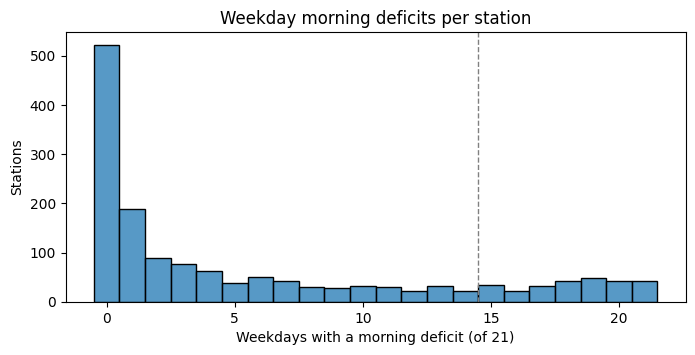

In [7]:
# Recurring-deficit stations: deficit on at least 15 of 21 weekdays
weekday = station_day[station_day["day_type"] == "Weekday"]
per_station = weekday.groupby("station_name").agg(
    weekday_deficit_days=("has_morning_deficit", "sum"),
    mean_morning_net_dep=("morning_net_departures", "mean"),
)
recurring = per_station[per_station["weekday_deficit_days"] >= 15]
print(f"{len(recurring)} recurring-deficit stations out of {len(per_station):,} active on weekdays")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=per_station, x="weekday_deficit_days", discrete=True, ax=ax)
ax.axvline(14.5, color="gray", ls="--", lw=1)
ax.set(xlabel="Weekdays with a morning deficit (of 21)", ylabel="Stations",
       title="Weekday morning deficits per station")
plt.show()

![Cumulative net flow at recurring-deficit stations](../figures/sean_cumulative_hourly_flow.png)

The 264 recurring-deficit stations are split into thirds by how often they fully recover by 8 p.m. Each line is the median station in its third, and the shading covers the middle 50%.

**What this shows so far:**

- 264 stations start the day short on at least 15 of 21 weekdays.
- At those stations, later traffic replaces about 62% of the morning loss overall, but the station fully recovers by 8 p.m. on only 39% of days.
- Recovery comes mostly from the 3–6 p.m. commute, and stations that rarely recover are still short at midnight.
- On weekends only about 10% of morning losses come back, compared with about 57% on weekdays.
- Recurring deficits are concentrated 2–5 km from the Loop (44% of stations there, vs 18% within 2 km and 5% beyond 10 km), mostly to the north and northwest (map below).
- Clustering the stations' daily curves with k-means finds 39 stations that keep losing bikes after 10 a.m.; they fully recover on only 19% of deficit days.

![Recurring-deficit stations colored by how often they fully recover](../figures/sean_station_map.png)

### Question 2: Do members and casual riders reinforce or offset each other's imbalances?
*By Daniel Cai*

Casual riders also net-depart on 49% of deficit station-days and net-arrive on 9%


,morning_net_departures,later_net_arrivals,share_of_morning_deficit
member_casual,,,
casual,6026,-311,0.2
member,23505,17049,0.8


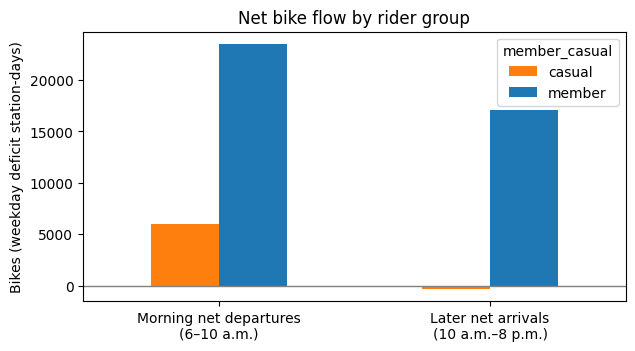

In [8]:
# Weekday deficit station-days (same sample as Question 1)
by_rider = pd.read_csv(DATA_PATH + "station_day_by_rider.csv")
keys = station_day.loc[(station_day["day_type"] == "Weekday") & station_day["has_morning_deficit"],
                       ["station_id", "day"]]
dr = by_rider.merge(keys, on=["station_id", "day"], how="inner", validate="many_to_one")

# Morning loss and later return by rider group
by_group = dr.groupby("member_casual")[["morning_net_departures", "later_net_arrivals"]].sum()
by_group["share_of_morning_deficit"] = by_group["morning_net_departures"] / by_group["morning_net_departures"].sum()

# Do casual riders add to or offset the deficit?
casual = dr[dr["member_casual"] == "casual"]
print(f"Casual riders also net-depart on {(casual['morning_net_departures'] > 0).sum() / len(keys):.0%} "
      f"of deficit station-days and net-arrive on {(casual['morning_net_departures'] < 0).sum() / len(keys):.0%}")
display(by_group.round(2))

ax = by_group[["morning_net_departures", "later_net_arrivals"]].T.plot.bar(
    color={"member": "tab:blue", "casual": "tab:orange"}, figsize=(7, 3.5), rot=0)
ax.axhline(0, color="gray", lw=1)
ax.set(xticklabels=["Morning net departures\n(6–10 a.m.)", "Later net arrivals\n(10 a.m.–8 p.m.)"],
       ylabel="Bikes (weekday deficit station-days)", title="Net bike flow by rider group")
plt.show()

**What this shows so far:**

- Casual riders add to the morning loss instead of canceling it out. They cause about 20% of it.
- Members bring the bikes back later in the day. Casual riders don't.
- Next: check weekends and bike type.

### Question 3: How much later inbound traffic comes back along the morning routes?
*By Surya Venkataraman*

In [9]:
trips = pd.read_csv(
    "../data/processed/trips_clean.csv",
    usecols=["started_at", "ended_at", "start_station_id", "end_station_id"],
    parse_dates=["started_at", "ended_at"],
)
n_all = len(trips)
trips = trips.dropna(subset=["start_station_id", "end_station_id"])
print(f"Trips with both station IDs: {len(trips):,} of {n_all:,} ({len(trips)/n_all:.1%})")

trips["dep_date"], trips["dep_hr"] = trips["started_at"].dt.date, trips["started_at"].dt.hour
trips["arr_date"], trips["arr_hr"] = trips["ended_at"].dt.date, trips["ended_at"].dt.hour


Trips with both station IDs: 500,502 of 751,315 (66.6%)


In [10]:
am_dep = trips[trips["dep_hr"].between(6, 9)].groupby(["dep_date", "start_station_id"]).size()
am_arr = trips[trips["arr_hr"].between(6, 9)].groupby(["arr_date", "end_station_id"]).size()
am_dep.index.names = am_arr.index.names = ["date", "station"]
net = am_dep.sub(am_arr, fill_value=0).rename("am_net_dep")
deficit = net[net > 0].reset_index()

In [11]:
am_routes = (trips[trips["dep_hr"].between(6, 9)]
             .groupby(["dep_date", "start_station_id", "end_station_id"]).size()
             .rename("am_trips").reset_index()
             .rename(columns={"dep_date": "date", "start_station_id": "station", "end_station_id": "other"}))


In [12]:
later = (trips[trips["arr_hr"].between(10, 19)]
         .groupby(["arr_date", "end_station_id", "start_station_id"]).size()
         .rename("later_arr").reset_index()
         .rename(columns={"arr_date": "date", "end_station_id": "station", "start_station_id": "other"}))
later = later.merge(am_routes, on=["date", "station", "other"], how="left")
later["reverse"] = later["am_trips"].notna()


In [13]:
sd = (later.assign(rev_arr=later["later_arr"] * later["reverse"])
      .groupby(["date", "station"])[["later_arr", "rev_arr"]].sum().reset_index())
sd = deficit.merge(sd, on=["date", "station"], how="left").fillna({"later_arr": 0, "rev_arr": 0})
sd["rev_share"] = sd["rev_arr"] / sd["later_arr"]
sd["rev_offset"] = sd["rev_arr"] / sd["am_net_dep"]

print(f"Deficit station-days: {len(sd):,} across {sd['station'].nunique():,} stations")
print(f"Pooled: {sd['rev_arr'].sum()/sd['later_arr'].sum():.1%} of later arrivals come back along morning routes")
print(f"Median reverse-route share (station-days with later arrivals): {sd['rev_share'].median():.1%}")
print(f"Median deficit offset by reverse routes alone: {sd['rev_offset'].median():.2f}")


Deficit station-days: 10,908 across 1,100 stations
Pooled: 12.8% of later arrivals come back along morning routes
Median reverse-route share (station-days with later arrivals): 7.1%
Median deficit offset by reverse routes alone: 0.33


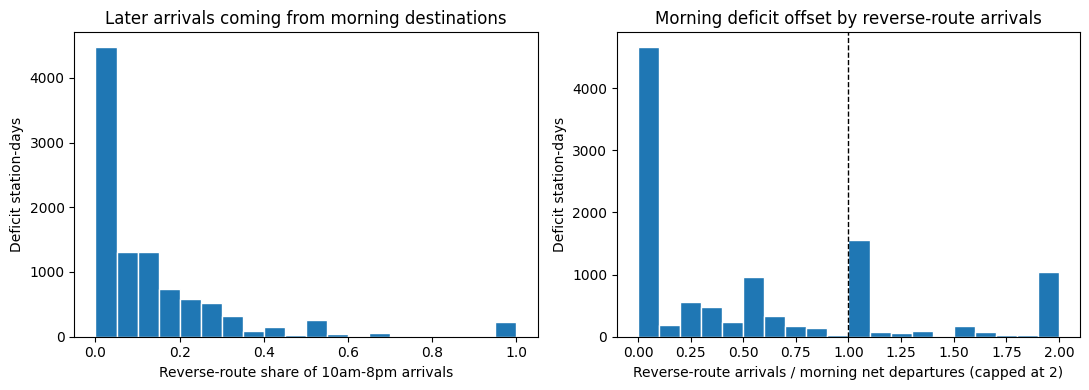

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(sd["rev_share"].dropna(), bins=20, edgecolor="white")
axes[0].set(title="Later arrivals coming from morning destinations",
            xlabel="Reverse-route share of 10am-8pm arrivals", ylabel="Deficit station-days")
axes[1].hist(sd["rev_offset"].clip(upper=2), bins=20, edgecolor="white")
axes[1].axvline(1, ls="--", c="k", lw=1)
axes[1].set(title="Morning deficit offset by reverse-route arrivals",
            xlabel="Reverse-route arrivals / morning net departures (capped at 2)", ylabel="Deficit station-days")
plt.tight_layout()
plt.show()

**What this shows so far:**

Among 10,908 morning-deficit station-days, 12.8% of 10am–8pm arrivals came from stations that received that station's 6–10am departures the same day. The median station gets just 7.1% of its later arrivals this way. For the typical deficit station-day, reverse-route arrivals alone replace about a third of the bikes lost in the morning (median ratio 0.33). Both histograms are dominated by station-days near zero, so most recovery comes from other stations, not the morning routes. The spikes at exactly 1.0 and at the cap of 2 are likely 1 or 2 bikes where a single return trip moves the ratio a lot.

Caveats: Route matching needs both station IDs, which keeps 66.6% of trips. Our deficit count (10,908) is slightly below the team's 11,408 for the same reason. Reverse-route trips are matches by route, not the same riders returning.

Next steps: (1) Build a baseline: compare with arrivals from the same destination stations on other days. This will allow us to check if this a commuter pattern or just a pattern of general movement. (2) Require a minimum number of morning trips before a destination counts. (3) Rerun for deficits of 5 or more bikes and for weekdays only.

### Question 4: How does recovery differ by rain, temperature, and weekday vs weekend?
*By Anjeli Noémi (Mimi)*

rainy      0.0  1.0
day_type           
Labor Day    1    0
Weekday     16    5
Weekend      6    2
                 station_days  full_recovery_rate  median_recovery
day_type  rain                                                    
Labor Day Dry             290               0.390              0.0
Weekday   Dry            6775               0.380              0.5
          Rainy          1773               0.412              0.5
Weekend   Dry            2099               0.333              0.0
          Rainy           471               0.382              0.0


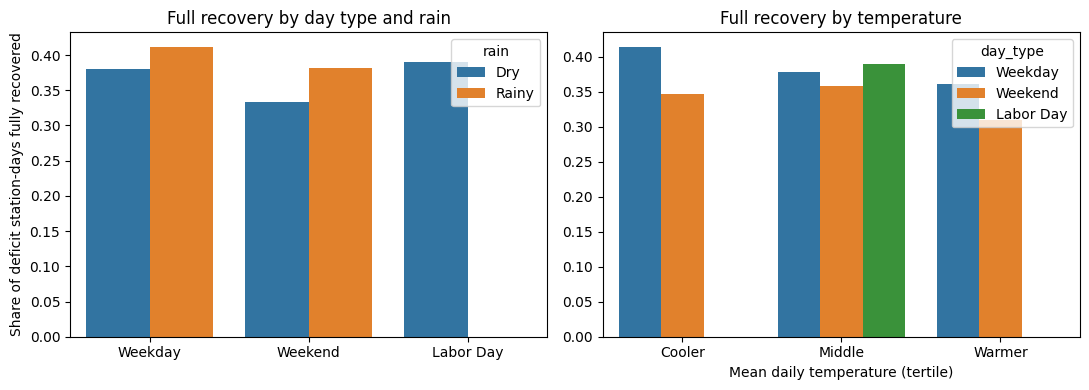

In [15]:
sd = pd.read_csv('../data/processed/station_day.csv')

# Only station-days that started the day short (recovery is defined for these)
deficit = sd[sd['has_morning_deficit']].copy()
deficit['rain'] = deficit['rainy'].map({0.0: 'Dry', 1.0: 'Rainy'})
deficit['temp_group'] = pd.qcut(deficit['temp_mean_c'], 3, labels=['Cooler', 'Middle', 'Warmer'])

# How many distinct days fall in each weather / day-type group?
days = sd.drop_duplicates('date')
print(pd.crosstab(days['day_type'], days['rainy']))

# Full-recovery rate by day type and rain
summary = (deficit.groupby(['day_type', 'rain'])
           .agg(station_days=('station_id', 'size'),
                full_recovery_rate=('full_recovery', 'mean'),
                median_recovery=('recovery', 'median'))
           .round(3))
print(summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=deficit, x='day_type', y='full_recovery', hue='rain', errorbar=None, ax=axes[0])
axes[0].set(title='Full recovery by day type and rain', xlabel='', ylabel='Share of deficit station-days fully recovered')
sns.barplot(data=deficit, x='temp_group', y='full_recovery', hue='day_type', errorbar=None, ax=axes[1])
axes[1].set(title='Full recovery by temperature', xlabel='Mean daily temperature (tertile)', ylabel='')
plt.tight_layout()
plt.savefig('../figures/mimi_recovery_weather_daytype.png', dpi=150, bbox_inches='tight')
plt.show()

**What this shows so far:**

- **Weekday vs weekend:** 38.6% of deficit station-days fully recover on weekdays, compared with 34.2% on weekends. The median recovery is 0.5 on weekdays (half the morning deficit comes back) but 0.0 on weekends.
- **Rain:** Surprisingly, rainy days show slightly *higher* full recovery than dry days, both on weekdays (41.2% vs 38.0%) and weekends (38.2% vs 33.3%), based on 7 rainy days. One possible reason is that rain reduces riding overall, so deficits are smaller and easier to make up. Daily precipitation also doesn't tell us *when* it rained.
- **Temperature:** Cooler weekdays have the highest full-recovery rate (about 41%); weekends are lower than weekdays at every temperature level.
- **Caveat:** Weather only varies by day, and September has 21 weekdays, 8 weekend days, and 1 Labor Day, with only 7 rainy days. The differences are only 3–5 percentage points, so these are early patterns, not conclusions.

## 3) What remains

| Task | Owner | Target date |
|---|---|---|
| Review shared cleaning choices (duration cutoffs, missing e-bike stations) | All | Wed, Nov 25 |
| Route baseline: compare reverse-route arrivals with the same stations on other days | Surya | Wed, Dec 2 |
| Rider contributions on weekends and by bike type | Daniel | Wed, Dec 2 |
| Finish each member's main figure, supporting table, and sensitivity check | Each member | Sun, Dec 6 |
| Slides and rehearsal | All | Thu, Dec 10 |
| Final report and code notebook | All | Fri, Dec 11, 11:59 pm |

**Biggest risk to finishing on time:** Thanksgiving break falls in the middle, so the route baseline and each member's sensitivity checks need to be done by Dec 6 to leave time for slides.

## 4) Questions for the mentor

1. Recovery (later net arrivals ÷ morning net departures) is unstable when the morning deficit is only 1–2 bikes. Should our main results use only deficits of at least 5 bikes, or is it enough to report the median, full-recovery rate, and pooled ratio together?
2. Weekday and weekend recovery differ a lot (57% vs 10% pooled). Should the station, rider, and route analyses use weekdays only and leave weekends to Mimi's question?
3. How long is each team's presentation in Session 2, and does every member present their own question?
4. What do you think of our four questions and how we split the work? Are there other charts or data mining methods (for example, clustering stations) you would suggest?

## Mentor feedback

- Make the charts more intuitive and readable.
- Explain the data wrangling and processing steps, rather than presenting the cleaned tables as given.